**This code runs each proposed experiment once using the best hyperparameter combination previously found in the grid search, for each batch size**

In [1]:
import pandas as pd
filepath='/data/temporalserie.csv'
datos_energia = pd.read_csv(filepath, parse_dates=True)
datos_energia['date'] = pd.to_datetime(datos_energia['date'], format='%Y-%m-%d')
datos_energia.set_index('date', inplace=True)
datos_energia.index

DatetimeIndex(['2012-01-01', '2012-01-02', '2012-01-03', '2012-01-04',
               '2012-01-05', '2012-01-06', '2012-01-07', '2012-01-08',
               '2012-01-09', '2012-01-10',
               ...
               '2023-05-22', '2023-05-23', '2023-05-24', '2023-05-25',
               '2023-05-26', '2023-05-27', '2023-05-28', '2023-05-29',
               '2023-05-30', '2023-05-31'],
              dtype='datetime64[ns]', name='date', length=4169, freq=None)

In [2]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torch.utils.data import Dataset, DataLoader
from torch.utils.data.sampler import SubsetRandomSampler
from torch.autograd import Variable

In [4]:
def train_val_test_split(dataframe, tr_size, vl_size, ts_size):
    N = dataframe.shape[0]
    Ntrain = int(tr_size*N)  
    Nval = int(vl_size*N)   
    Ntst = N - Ntrain - Nval
   
    train = dataframe[0:Ntrain]
    val = dataframe[Ntrain:Ntrain+Nval]
    test = dataframe[Ntrain+Nval:]

    return train, val, test


trs=0.8
vls=0.1
tss=0.1
tr, vl, ts = train_val_test_split(datos_energia,trs,vls,tss)

In [6]:
scaler = MinMaxScaler(feature_range=(0, 1))
tr_input=tr.to_numpy()
vl_input=vl.to_numpy()
ts_input=ts.to_numpy()

train_normalized = scaler.fit_transform(tr_input)
val_normalized = scaler.transform(vl_input)
test_normalized = scaler.transform(ts_input)

In [8]:
def create_temporal_split(input_data, tw, ftw):
    inout_seq = []
    inout_label = []
    L = len(input_data)
    for i in range(0, L - (tw + ftw)):
        seq = input_data[i : i + tw + ftw, :-1]            
        label = input_data[i+tw : i+tw+ftw, -1]  
        inout_seq.append(seq)
        inout_label.append(label)
    return inout_seq, inout_label

In [9]:
class Create_Dataset(Dataset):
    def __init__(self, X, Y):
        if not torch.is_tensor(X):
            self.X = torch.Tensor(X)
        if not torch.is_tensor(Y):
            self.Y = torch.Tensor(Y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

In [10]:
#Set temporal and future windows values
tw=7
ftw=1 # used 7 and 14 too

x_train, y_train = create_temporal_split(train_normalized, tw, ftw)
x_validation, y_validation = create_temporal_split(val_normalized, tw, ftw)
x_test, y_test = create_temporal_split(test_normalized, tw, ftw)

In [11]:
train_set = Create_Dataset(x_train, y_train)
validation_set = Create_Dataset(x_validation, y_validation)
test_set = Create_Dataset(x_test, y_test)

batch_size = 4 #Tested with 4, 8, 10, 16, 32 values

train_loader = DataLoader(train_set, batch_size=batch_size,shuffle=False,num_workers=2, drop_last=True)
validation_loader = DataLoader(validation_set, batch_size=batch_size,shuffle=False,num_workers=2, drop_last=True)
test_loader = DataLoader(test_set, batch_size=batch_size,shuffle=False,num_workers=2, drop_last=True)

/tmp/ipykernel_75681/3711736301.py:5: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:278.)
  self.X = torch.Tensor(X)


In [3]:
is_cuda = torch.cuda.is_available()
if is_cuda:
    device = torch.device("cuda")
    print("GPU available")
else:
    device = torch.device("cpu")
    print("GPU not available, using CPU")

GPU not available, using CPU


**Modelo LSTM**

In [13]:
class Model(nn.Module):
    def __init__(self, capas, hidden_dim, out_days):
    #def __init__(self, hidden_dim, out_days):
        super(Model, self).__init__()        
        self.input_size = 20 
        self.hidden_dim = hidden_dim  
        self.n_layers = capas
        self.lstm = nn.LSTM(input_size = self.input_size,hidden_size= self.hidden_dim,
                             num_layers=self.n_layers, batch_first=True)
        self.fc = nn.Linear(self.hidden_dim, out_days)

    def forward(self, x):
        batch_size = x.size(0)
        hidden, cell = self.init_hidden(batch_size)
        out_lstm, (hidden,cell) = self.lstm(x, (hidden,cell))
        final = hidden[-1]
        out = self.fc(final)
        return out

    def init_hidden(self, batch_size):
        hidden = torch.zeros(self.n_layers, batch_size, self.hidden_dim).to(device)
        cell = torch.zeros(self.n_layers, batch_size, self.hidden_dim).to(device)
        return hidden, cell

In [15]:
# Definimos las funciones de entrenamiento y evaluación
def train(model,loader):
    total_loss = 0.0
    for data in loader:
        model.train()
        inputs, targets = data
        inputs = inputs.to(device)
        targets = targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs.view(batch_size,train_window+ftw,-1))
        loss = criterion(outputs,targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * inputs.size(0)
    total_loss/= len(loader.dataset)
    return total_loss


def test(model,loader):
    model.eval()
    total_loss = 0.0
    for data in loader:
        inputs, targets = data
        inputs = inputs.to(device)
        targets = targets.to(device)
        with torch.no_grad():
            outputs = model(inputs.view(batch_size,train_window+ftw,-1))
        loss = criterion(outputs,targets)
        total_loss += loss.item() * inputs.size(0)
    total_loss/= len(loader.dataset)
    return total_loss

In [14]:
#Best Hyperparameters for each experiment
lr=0.001
patience = 150
layers=3
neurons=5
days_predict=1
n_epochs = 300
model=Model(layers,neurons,days_predict)  
model.to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

Entreno el modelo

In [16]:
best_val_loss = 10000.0
best_train_loss = 10000.0
j = 0 
epoch = 0 
best_epoch=0
loss_list_train = [] 
loss_list_val = [] 
selected_model_state_dict = model.state_dict() 

while ((epoch < n_epochs) and (j < patience)):
    train_loss= train(model,train_loader)   
    validation_loss = test(model, validation_loader) 
    loss_list_train.append(train_loss)
    loss_list_val.append(validation_loss)
    if epoch%10 == 0:
        print('Epoca: {}/{}.............'.format(epoch, n_epochs), end=' ')
        print("Train loss: {:.4f}".format(train_loss), ", Validation loss: {:.4f}".format(validation_loss))   
    if (validation_loss <= best_val_loss):
        best_epoch = epoch
        best_train_loss = train_loss
        best_val_loss = validation_loss
        selected_model_state_dict = model.state_dict()
        j = 0 
    else:
        j += 1 

    epoch += 1 

print('La mejor Epoca fue {:03d}, Train loss: {:.4f}, Validation loss: {:.4f}'.format(
              best_epoch, best_train_loss, best_val_loss))
model.load_state_dict(selected_model_state_dict)

Epoca: 0/300............. Train loss: 0.0301 , Validation loss: 0.0454
Epoca: 10/300............. Train loss: 0.0116 , Validation loss: 0.0167
Epoca: 20/300............. Train loss: 0.0057 , Validation loss: 0.0057
Epoca: 30/300............. Train loss: 0.0045 , Validation loss: 0.0047
Epoca: 40/300............. Train loss: 0.0040 , Validation loss: 0.0042
Epoca: 50/300............. Train loss: 0.0037 , Validation loss: 0.0041
Epoca: 60/300............. Train loss: 0.0035 , Validation loss: 0.0041
Epoca: 70/300............. Train loss: 0.0034 , Validation loss: 0.0040
Epoca: 80/300............. Train loss: 0.0032 , Validation loss: 0.0039
Epoca: 90/300............. Train loss: 0.0030 , Validation loss: 0.0038
Epoca: 100/300............. Train loss: 0.0029 , Validation loss: 0.0038
Epoca: 110/300............. Train loss: 0.0028 , Validation loss: 0.0037
Epoca: 120/300............. Train loss: 0.0027 , Validation loss: 0.0037
Epoca: 130/300............. Train loss: 0.0026 , Validation lo

<All keys matched successfully>

In [17]:
import pickle

# Guardar loss_list_train y loss_list_val a disco
with open('/data/loss_lists.pkl', 'wb') as f:    
    pickle.dump((loss_list_train, loss_list_val), f)


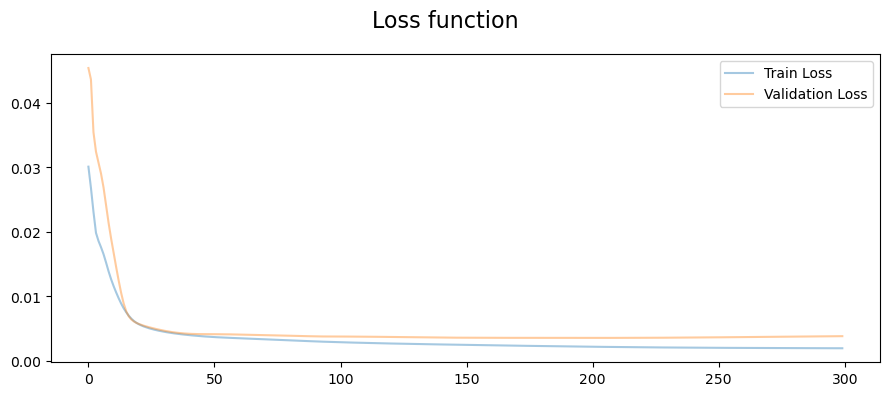

In [18]:
fig = plt.figure(figsize=(9, 4))
loss_train_array = np.array(loss_list_train)
loss_val_array = np.array(loss_list_val)
plt.plot(loss_train_array, alpha = 0.4, label='Train Loss')
plt.plot(loss_val_array, alpha = 0.4, label='Validation Loss')
plt.legend()
plt.suptitle('Loss function', fontsize=16)
plt.tight_layout()
fig.savefig('/data/lossfunction.png', dpi=300)
plt.show()

In [19]:
model.eval()
all_test_inputs = torch.Tensor(x_test)
all_test_inputs = all_test_inputs.to(device)
all_test_outputs = model(all_test_inputs)
y_preds_test = all_test_outputs.data.cpu().numpy()
test_loss = test(model, test_loader)
print("Test loss =", test_loss)

all_val_inputs = torch.Tensor(x_validation)
all_val_inputs = all_val_inputs.to(device)
all_val_outputs = model(all_val_inputs)
y_preds_val = all_val_outputs.data.cpu().numpy()

all_train_inputs = torch.Tensor(x_train)
all_train_inputs = all_train_inputs.to(device)
all_train_outputs = model(all_train_inputs)
y_preds_train = all_train_outputs.data.cpu().numpy()

Test loss = 0.00551206551992493


In [20]:
from sklearn.metrics import mean_squared_error, r2_score
rmse_train = np.sqrt(mean_squared_error(y_train, y_preds_train))
r2_train = r2_score(y_train, y_preds_train)
corr_train = np.corrcoef(y_train, y_preds_train)

print("Train RMSE =", rmse_train)
print("Train R^2 =", r2_train)

rmse_val = np.sqrt(mean_squared_error(y_validation, y_preds_val))
r2_val = r2_score(y_validation, y_preds_val)
print("Validation RMSE =", rmse_val)
print("Validation R^2 =", r2_val)

rmse_test = np.sqrt(mean_squared_error(y_test, y_preds_test))
r2_test = r2_score(y_test, y_preds_test)
print("Test RMSE =", rmse_test)
print("Test R^2 =", r2_test)

/usr/lib64/python3.12/site-packages/numpy/lib/function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/usr/lib64/python3.12/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/lib64/python3.12/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


Train RMSE = 0.05318705307810393
Train R^2 = 0.89649498462677
Validation RMSE = 0.06212359040345214
Validation R^2 = 0.9042575359344482
Test RMSE = 0.07430297707184813
Test R^2 = 0.9056895971298218


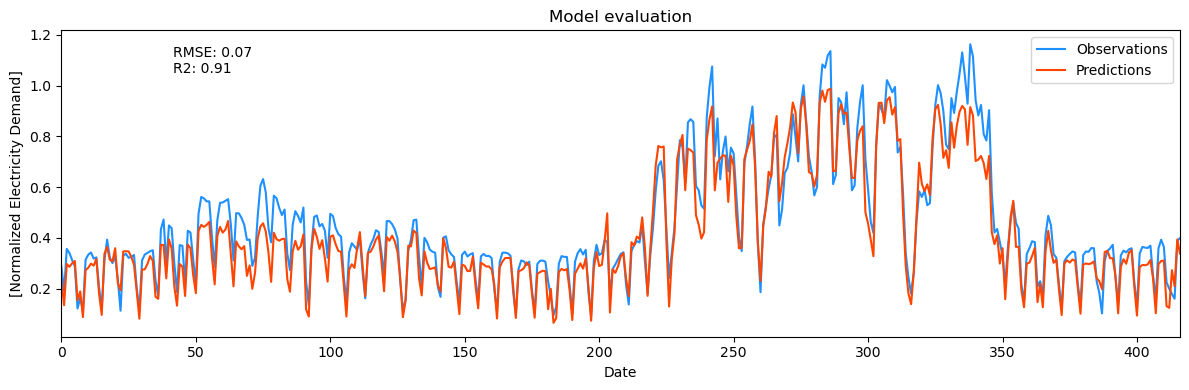

In [25]:
import matplotlib.pyplot as plt
# Crear la gráfica
plt.figure(figsize=(12, 4))
plt.plot(y_test, label='Observations', color='dodgerblue')
plt.plot(y_preds_test, label='Predictions', color='orangered')

# Texto con información de RMSE y R^2
info_lin_rmse = f'RMSE: {rmse_test:.2f}\nR2: {r2_test:.2f}'
# Ajustar límites del eje X
plt.xlim(0, len(y_test) - 1)
# Coordenadas iniciales para el texto
x_start = 0.1
y_start = 0.9
line_space = 0.04

# Agregar texto de RMSE
plt.text(x_start, y_start, info_lin_rmse, horizontalalignment='left', verticalalignment='center', transform=plt.gca().transAxes)
plt.xlabel('Date')
plt.ylabel('[Normalized Electricity Demand]')
plt.title('Model evaluation')
plt.legend()
plt.tight_layout()
plt.savefig('/data/prediccion.png', dpi=300)
plt.show()

In [26]:
import pickle

# Guardar el modelo
with open('/data/model_trained.pkl', 'wb') as f:
    pickle.dump(model, f)

resultados = {
    'y_train': y_train,
    'y_preds_train': y_preds_train,
    'y_validation': y_validation,
    'y_preds_val': y_preds_val,
    'y_test': y_test,
    'y_preds_test': y_preds_test,
    'train_rmse': rmse_train,
    'train_r2': r2_train,
    'validation_rmse': rmse_val,
    'validation_r2': r2_val,
    'test_rmse': rmse_test,
    'test_r2': r2_test
}

with open('/data/results_pred_metrics.pkl', 'wb') as f:
    pickle.dump(resultados, f)

In [27]:
import pandas as pd

pri_values = [arr[0] for arr in y_test]
pri_preds = [arr[0] for arr in y_preds_test]

# Crear un DataFrame para los valores de prueba y predicciones
test_data = pd.DataFrame({
    'y_test': pri_values,
    'y_preds': pri_preds,
 
})

# Guardar el DataFrame de valores de prueba y predicciones en un archivo CSV
test_data.to_csv('/data/test_predictions.csv', index=False)

# Crear un DataFrame para las métricas
metrics_data = pd.DataFrame([{
    'Train RMSE': rmse_train,
    'Train R2': r2_train,
    'Val RMSE': rmse_val,
    'Val R2': r2_val,
    'Test RMSE': rmse_test,
    'Test R2': r2_test,
  
}])

# Guardar el DataFrame de métricas en un archivo CSV
metrics_data.to_csv('/data/metrics.csv', index=False)

In [34]:
#Cargar los datos
data = pd.read_csv('/data/test_predictions.csv')
metrics_data = pd.read_csv('/data/metrics.csv')
print(metrics_data)

   Train RMSE  Train R2  Val RMSE    Val R2  Test RMSE  Test R2
0    0.053187  0.896495  0.062124  0.904258   0.074303  0.90569


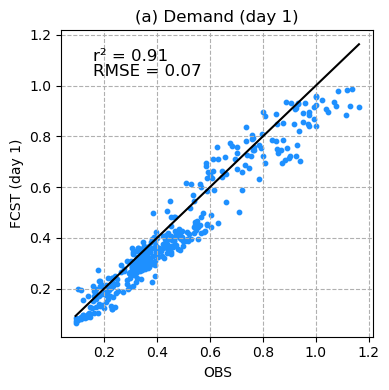

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(4, 4))

axes.scatter(data['y_test'], data['y_preds'], color='dodgerblue', s=10)
axes.plot([min(data['y_test']), max(data['y_test'])], 
               [min(data['y_test']), max(data['y_test'])], color='black')
axes.set_xlabel('OBS')
axes.set_ylabel('FCST (day 1)')
axes.set_title('(a) Demand (day 1)')
axes.grid(linestyle='--')

r2_dia1 = metrics_data['Test R2'].values[0] 
rmse_dia1 = metrics_data['Test RMSE'].values[0] 

# Agregar texto con las métricas al gráfico
axes.text(0.1, 0.9, f'r² = {r2_dia1:.2f}', transform=axes.transAxes,fontsize=12)
axes.text(0.1, 0.85, f'RMSE = {rmse_dia1:.2f}', transform=axes.transAxes, fontsize=12,)

# Ajustar el espaciado entre subplots
plt.tight_layout()
plt.savefig('/data/day1.png', dpi=300)
plt.show()

In [67]:
import pickle

# Ruta del archivo
file_path = "/home/marielauhrig/Documents/LSTM/MiProyecto/resultados_tw7_ftw1/MejorB32/results_pred_metrics.pkl"


# Cargar el archivo pickle
with open(file_path, "rb") as f:
    data_dict = pickle.load(f)

# Ver las claves del diccionario
print(data_dict.keys())

dict_keys(['y_train', 'y_preds_train', 'y_validation', 'y_preds_val', 'y_test', 'y_preds_test', 'train_rmse', 'train_r2', 'validation_rmse', 'validation_r2', 'test_rmse', 'test_r2'])


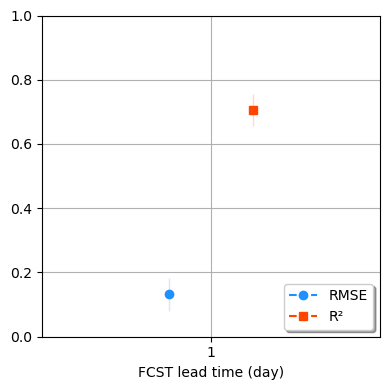

In [68]:
import matplotlib.pyplot as plt
import numpy as np

# Crear la figura
plt.figure(figsize=(4, 4))
x_axis = np.array([1])  
rmse_value = data_dict['test_rmse']
r2_value = data_dict['test_r2']
x_rmse = x_axis - 0.05
x_r2 = x_axis + 0.05    
rmse_upper = rmse_value + 0.05
rmse_lower = rmse_value - 0.05
r2_upper = r2_value + 0.05
r2_lower = r2_value - 0.05
plt.plot(x_rmse, rmse_value, marker='o', linestyle='--', label='RMSE', color='dodgerblue')
plt.fill_between(x_rmse, rmse_lower, rmse_upper, color='dodgerblue', alpha=0.2)
plt.plot(x_r2, r2_value, marker='s', linestyle='--', label='R²', color='orangered')
plt.fill_between(x_r2, r2_lower, r2_upper, color='orangered', alpha=0.2)
plt.xlabel('FCST lead time (day)')
plt.xticks([1]) 
plt.ylim(0, 1)
plt.xlim(0.8, 1.2)  
plt.grid(True)
plt.legend(loc='lower right', frameon=True, shadow=True)
plt.tight_layout()
plt.savefig('/data/FCST_rmse_r2.png', dpi=300)
plt.show()
